# Etapa 2: Transformação numérica e redução de dimensionalidade

Nesta parte da Etapa 2 eu cuido da escala dos atributos numéricos. Parti da base limpa da Pessoa 1 (`treino_limpo.csv`) e da imputação e codificação escolhidas pela Pessoa 2, e comparei:

1. **transformação** com `log1p` nos atributos muito assimétricos (bytes e duração, como pede o enunciado, e uma variante com todas as contagens);
2. **escala** com `StandardScaler` × `RobustScaler` (e sem escala, como referência);
3. **redução de dimensionalidade** com PCA.

Tudo fica dentro de um `Pipeline`, então o `log1p`, os escaladores e o PCA só são ajustados no treino de cada fold. As peças ficam no arquivo `transformacao.py`, para a Pessoa 4 juntar no notebook final. A seção inteira leva uns 40 minutos para rodar, por causa dos 3 modelos em 10 folds.

## 0. Leitura dos dados e avaliação

In [1]:
from pathlib import Path
from time import perf_counter
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate

import transformacao as T   # as peças desta parte ficam em transformacao.py

warnings.filterwarnings("ignore", category=UserWarning)   # aviso de categoria desconhecida no one-hot
pd.set_option("display.max_columns", 60)
AZUL, LARANJA, CINZA = "#2a6fdb", "#d95f02", "#8a8a8a"

PASTA = Path("BANCO_DE_DADOS")
treino_limpo = pd.read_csv(PASTA / "treino_limpo.csv")
X, y = T.separar(treino_limpo)    # tira class e score_ids_legado
NUM = T.colunas_numericas(X)

print("X:", X.shape, f"| anomalias: {y.mean() * 100:.2f}%")
print(f"{len(NUM)} numéricas e {len(T.CATEGORICAS)} categóricas")

X: (55074, 40) | anomalias: 3.30%
37 numéricas e 3 categóricas


- **O que vem da Pessoa 2:** mediana nos números, moda nos textos e `service` em one-hot com os serviços raros juntos. `T.montar_preprocessador` usa essas mesmas peças de `ausentes_codificacao.py`; o que muda aqui é só o tratamento dos números.
- **Validação:** a mesma da Pessoa 2, 5 folds estratificados repetidos 2 vezes, com os mesmos folds para todas as técnicas. Por isso, além da média, conto em quantos dos 10 folds cada técnica ganhou da referência. A `avaliar()` da Pessoa 1 ainda não saiu, então uso uma provisória. Ela se chama `avaliar_p3` para não tapar a oficial no notebook do grupo.
- **Modelos:** regressão logística e random forest, os mesmos da Pessoa 2, mais o **KNN**, porque ele trabalha com distâncias e é o mais sensível à escala. O SMOTE da Pessoa 4 também usa distâncias.
- **`score_ids_legado` ficou de fora**, como na Pessoa 2, até o grupo decidir se ela é vazamento.

**Regra de escolha:** a mesma da Pessoa 2, adaptada para três modelos. A técnica não pode ter média menor que a referência em nenhum modelo e precisa ganhar em pelo menos 8 dos 10 folds em pelo menos um. Se nenhuma passar, fico com a referência.

In [2]:
CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=42)   # os mesmos folds da Pessoa 2

MODELOS_P3 = {
    "Regressão logística": LogisticRegression(max_iter=2000),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Random forest": RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42),
}


# provisória, até a avaliar() da Pessoa 1 ficar pronta
def avaliar_p3(pipeline, X=X, y=y):
    return cross_validate(pipeline, X, y, cv=CV, scoring="f1_macro", n_jobs=-1)


def comparar_p3(tecnicas, referencia):
    """tecnicas = {nome: pré-processamento}. Roda cada uma em cada modelo e compara
    com a referência fold a fold (os folds são os mesmos para todas)."""
    linhas, folds = [], {}
    for nome_m, modelo in MODELOS_P3.items():
        for nome, pre in tecnicas.items():
            r = avaliar_p3(Pipeline([("pre", pre), ("modelo", modelo)]))
            folds[nome_m, nome] = r["test_score"]
            linhas.append({"modelo": nome_m, "técnica": nome, "f1_macro": r["test_score"].mean(),
                           "desvio": r["test_score"].std(), "treino_s": r["fit_time"].mean()})
    res = pd.DataFrame(linhas)
    dif = [folds[m, t] - folds[m, referencia] for m, t in zip(res["modelo"], res["técnica"])]
    res["dif"] = [d.mean() for d in dif]
    res["ganhou"] = [int((d > 0).sum()) for d in dif]
    return res


def regra_p3(res, referencia, min_folds=8):
    """Mostra a diferença para a referência e quem passa na regra de escolha."""
    tab = res.assign(cel=res["dif"].map("{:+.4f}".format) + " (" + res["ganhou"].astype(str) + "/10)") \
             .pivot(index="técnica", columns="modelo", values="cel").loc[res["técnica"].unique(), list(MODELOS_P3)]
    tab["passa"] = (res[res["dif"] >= 0].groupby("técnica").size().reindex(tab.index, fill_value=0) == len(MODELOS_P3)) \
                   & (res.groupby("técnica")["ganhou"].max().reindex(tab.index) >= min_folds)
    tab = tab.astype({"passa": object})
    tab.loc[referencia, :] = "referência"
    display(tab)
    return [t for t in tab.index if tab.loc[t, "passa"] is True or tab.loc[t, "passa"] == True]

## 1. Por que `log1p`?

Antes de transformar, olho a assimetria (*skewness*) das numéricas. Uma distribuição simétrica tem assimetria perto de 0; acima de 1 já é bem assimétrica. O `log1p(x) = log(1 + x)` comprime os valores grandes e funciona com zero, que é o valor mais comum nessas colunas.

In [3]:
assim = X[NUM].skew()
resumo = pd.DataFrame({
    "assimetria": assim,
    "% zeros": (X[NUM] == 0).mean() * 100,
    "mediana": X[NUM].median(),
    "máximo": X[NUM].max(),
}).sort_values("assimetria", ascending=False)
resumo["log1p na variante contagens"] = resumo.index.isin(T.COLS_LOG_CONTAGENS)
display(resumo.round(2).head(20))
print("colunas 0/1:", [c for c in NUM if set(X[c].dropna().unique()) <= {0, 1}])

,assimetria,% zeros,mediana,máximo,log1p na variante contagens
is_host_login,234.68,100.00,0.0,1.0,False
dst_bytes,215.03,17.28,386.0,209228000.0,True
duration,182.59,87.48,0.0,39603000.0,True
num_root,177.83,99.20,0.0,7468.0,True
urgent,149.46,99.99,0.0,3.0,True
src_bytes,101.58,4.30,227.0,21945520.0,True
land,88.69,99.99,0.0,1.0,False
num_file_creations,65.44,94.39,0.0,100.0,True
num_shells,49.69,99.95,0.0,2.0,True
num_compromised,49.39,93.23,0.0,10300.0,True


colunas 0/1: ['land', 'logged_in', 'root_shell', 'su_attempted', 'is_host_login', 'is_guest_login']


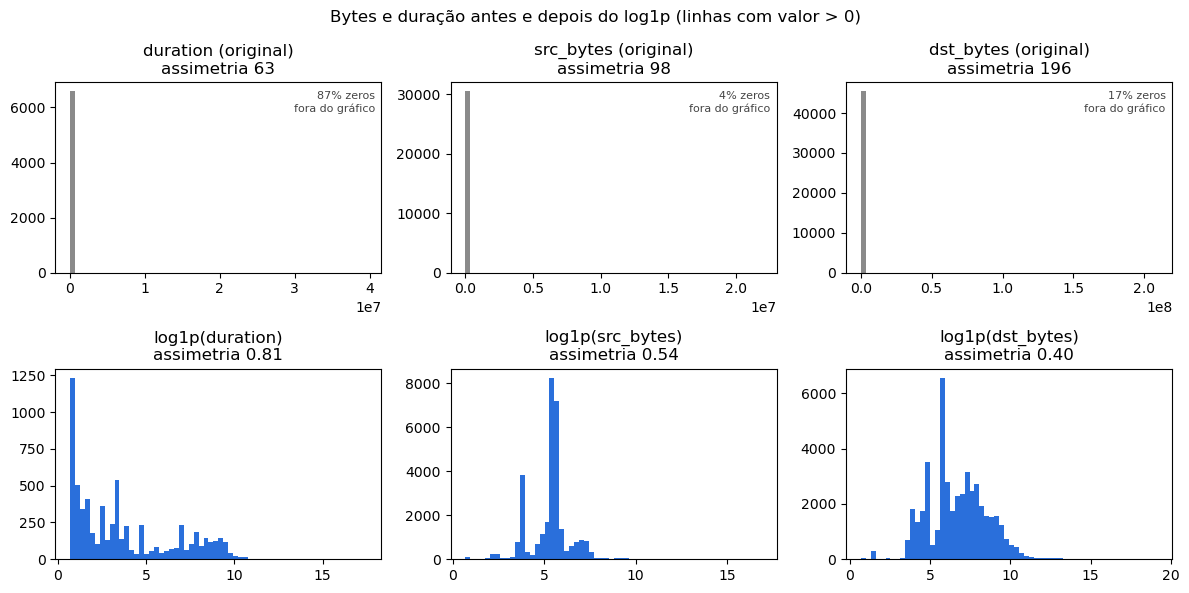

In [4]:
# gráfico 1: bytes e duração antes e depois do log1p (só valores > 0, senão o zero domina)
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for j, c in enumerate(T.COLS_LOG_BYTES):
    v = X[c].dropna()
    v = v[v > 0]
    axes[0, j].hist(v, bins=60, color=CINZA)
    axes[0, j].set_title(f"{c} (original)\nassimetria {v.skew():.0f}")
    axes[1, j].hist(np.log1p(v), bins=60, color=AZUL)
    axes[1, j].set_title(f"log1p({c})\nassimetria {np.log1p(v).skew():.2f}")
    axes[0, j].text(0.98, 0.95, f"{(X[c] == 0).mean():.0%} zeros\nfora do gráfico", transform=axes[0, j].transAxes,
                    ha="right", va="top", fontsize=8, color="#444")
fig.suptitle("Bytes e duração antes e depois do log1p (linhas com valor > 0)")
plt.tight_layout(); plt.show()

**Conclusão da seção 1**

- Os bytes e a duração estão entre as colunas mais assimétricas da base: `dst_bytes` tem assimetria 215, `duration` 183 e `src_bytes` 102. Os máximos chegam a 209 milhões de bytes e 39,6 milhões de segundos, enquanto as medianas são 386, 0 e 227.
- Olhando só os valores acima de zero, o `log1p` derruba a assimetria para menos de 1 nas três (0,81 na duração, 0,54 em `src_bytes` e 0,40 em `dst_bytes`). O gráfico mostra a diferença: antes quase tudo fica espremido numa barra perto do zero; depois aparece a distribuição de verdade.
- `duration` é zero em 87% das linhas. O `log1p` mantém o zero como zero, então essas linhas não mudam.
- Outras contagens também são muito assimétricas (`num_root`, `num_compromised`, `num_file_creations`, `hot`...). Por isso testo também uma variante com `log1p` em **todas as contagens** (16 colunas que não são taxa nem 0/1). As taxas já ficam entre 0 e 1 e as seis colunas 0/1 não têm o que comprimir, então ficam de fora.

## 2. Por que o `RobustScaler` pode não ajudar aqui

O `StandardScaler` subtrai a média e divide pelo desvio padrão. O `RobustScaler` subtrai a mediana e divide pelo intervalo interquartil (IQR = Q3 − Q1), que não é afetado por valores extremos. O problema é quando o IQR é **zero**: aí o sklearn não divide por nada (escala 1), e a coluna fica com os valores originais. Conto quantas colunas estão nessa situação.

In [5]:
q1, q3 = X[NUM].quantile(0.25), X[NUM].quantile(0.75)
iqr = q3 - q1
iqr_zero = iqr[iqr == 0].index.tolist()
print(f"{len(iqr_zero)} de {len(NUM)} numéricas têm IQR = 0")
display(pd.DataFrame({"IQR": iqr[iqr_zero], "máximo": X[iqr_zero].max()})
        .sort_values("máximo", ascending=False).head(10))

25 de 37 numéricas têm IQR = 0


,IQR,máximo
duration,0.0,39603000.0
num_compromised,0.0,10300.0
num_root,0.0,7468.0
hot,0.0,101.0
num_file_creations,0.0,100.0
num_access_files,0.0,9.0
num_failed_logins,0.0,4.0
urgent,0.0,3.0
wrong_fragment,0.0,3.0
num_shells,0.0,2.0


**Conclusão da seção 2**

- 25 das 37 numéricas têm IQR = 0, porque mais de 75% das linhas têm o mesmo valor (quase sempre zero). Nelas o `RobustScaler` só subtrai a mediana e **não muda a escala**.
- Entre elas estão justamente as colunas com valores extremos: `duration` (até 39,6 milhões), `num_compromised` (até 10.300) e `num_root` (até 7.468). Sem `log1p`, esses valores entram no modelo praticamente do jeito que vieram, e a expectativa é que o `RobustScaler` vá mal nesse caso. A seção 3 confirma.

## 3. Comparação: `log1p` × escala

Cruzo três opções de `log1p` (nenhum, só bytes e duração, todas as contagens) com três de escala (nenhuma, `StandardScaler`, `RobustScaler`), nos três modelos. São 27 combinações, cada uma com 10 folds. A **referência** é o que a Pessoa 2 usou até aqui: sem `log1p` e com `StandardScaler`. Ela tem que dar os mesmos 0,9308 e 0,9750 da tabela da Pessoa 2, o que serve de conferência.

In [6]:
OPCOES_LOG = {
    "sem log1p": [],
    "log1p bytes e duração": T.COLS_LOG_BYTES,
    "log1p todas as contagens": T.COLS_LOG_CONTAGENS,
}
ESCALAS = {"sem escala": "nenhum", "StandardScaler": "standard", "RobustScaler": "robust"}
REF_ESCALA = "sem log1p | StandardScaler"

comp = comparar_p3({f"{nome_log} | {nome_esc}": T.montar_preprocessador(cols, esc)
                    for nome_log, cols in OPCOES_LOG.items() for nome_esc, esc in ESCALAS.items()}, REF_ESCALA)
comp[["log1p", "escala"]] = comp["técnica"].str.split(" | ", regex=False, expand=True)

# conferência: a referência é o pipeline da Pessoa 2
r = comp[comp["técnica"] == REF_ESCALA].set_index("modelo")["f1_macro"]
print(f"referência: logística {r['Regressão logística']:.4f} (Pessoa 2: 0.9308) | random forest {r['Random forest']:.4f} (Pessoa 2: 0.9750)")

# tabela: F1-macro médio ± desvio entre os folds
comp["F1-macro"] = comp["f1_macro"].map("{:.4f}".format) + " ± " + comp["desvio"].map("{:.4f}".format)
tabela = comp.pivot(index=["modelo", "log1p"], columns="escala", values="F1-macro")
display(tabela.loc[[(m, l) for m in MODELOS_P3 for l in OPCOES_LOG], list(ESCALAS)])

referência: logística 0.9308 (Pessoa 2: 0.9308) | random forest 0.9750 (Pessoa 2: 0.9750)


escala                                             sem escala  \
modelo              log1p                                       
Regressão logística sem log1p                 0.8942 ± 0.0122   
                    log1p bytes e duração     0.9324 ± 0.0049   
                    log1p todas as contagens  0.9387 ± 0.0053   
KNN (k=5)           sem log1p                 0.9012 ± 0.0044   
                    log1p bytes e duração     0.8812 ± 0.0083   
                    log1p todas as contagens  0.9519 ± 0.0076   
Random forest       sem log1p                 0.9750 ± 0.0040   
                    log1p bytes e duração     0.9750 ± 0.0041   
                    log1p todas as contagens  0.9751 ± 0.0043   

escala                                         StandardScaler     RobustScaler  
modelo              log1p                                                       
Regressão logística sem log1p                 0.9308 ± 0.0057  0.8292 ± 0.0570  
                    log1p bytes e duração     0.9342 ± 0.0055  0.9325 ± 0.0043  
                    log1p todas as contagens  0.9386 ± 0.0054  0.9381 ± 0.0050  
KNN (k=5)           sem log1p                 0.9508 ± 0.0061  0.9151 ± 0.0071  
                    log1p bytes e duração     0.9533 ± 0.0062  0.9232 ± 0.0074  
                    log1p todas as contagens  0.9588 ± 0.0061  0.9272 ± 0.0062  
Random forest       sem log1p                 0.9750 ± 0.0041  0.9748 ± 0.0040  
                    log1p bytes e duração     0.9749 ± 0.0043  0.9748 ± 0.0041  
                    log1p todas as contagens  0.9751 ± 0.0043  0.9751 ± 0.0043

In [7]:
# diferença para a referência e folds ganhos (de 10), em cada modelo
passam = regra_p3(comp, REF_ESCALA)
print("Passam na regra:", passam)

# tempo médio de treino por fold (s) na regressão logística: sem escala o otimizador demora a convergir
display(comp[comp["modelo"] == "Regressão logística"]
        .pivot(index="log1p", columns="escala", values="treino_s").loc[list(OPCOES_LOG), list(ESCALAS)].round(1))

modelo,Regressão logística,KNN (k=5),Random forest,passa
técnica,,,,
sem log1p | sem escala,-0.0366 (0/10),-0.0496 (0/10),+0.0000 (2/10),False
sem log1p | StandardScaler,referência,referência,referência,referência
sem log1p | RobustScaler,-0.1016 (0/10),-0.0357 (0/10),-0.0002 (1/10),False
log1p bytes e duração | sem escala,+0.0016 (7/10),-0.0696 (0/10),+0.0000 (3/10),False
log1p bytes e duração | StandardScaler,+0.0033 (9/10),+0.0025 (7/10),-0.0001 (1/10),False
log1p bytes e duração | RobustScaler,+0.0017 (7/10),-0.0276 (0/10),-0.0002 (2/10),False
log1p todas as contagens | sem escala,+0.0078 (10/10),+0.0010 (7/10),+0.0001 (4/10),True
log1p todas as contagens | StandardScaler,+0.0078 (10/10),+0.0079 (10/10),+0.0002 (4/10),True
log1p todas as contagens | RobustScaler,+0.0073 (10/10),-0.0236 (0/10),+0.0001 (4/10),False


Passam na regra: ['log1p todas as contagens | sem escala', 'log1p todas as contagens | StandardScaler']


escala,sem escala,StandardScaler,RobustScaler
log1p,,,
sem log1p,111.2,6.4,119.0
log1p bytes e duração,94.7,5.9,38.2
log1p todas as contagens,6.0,6.5,29.8


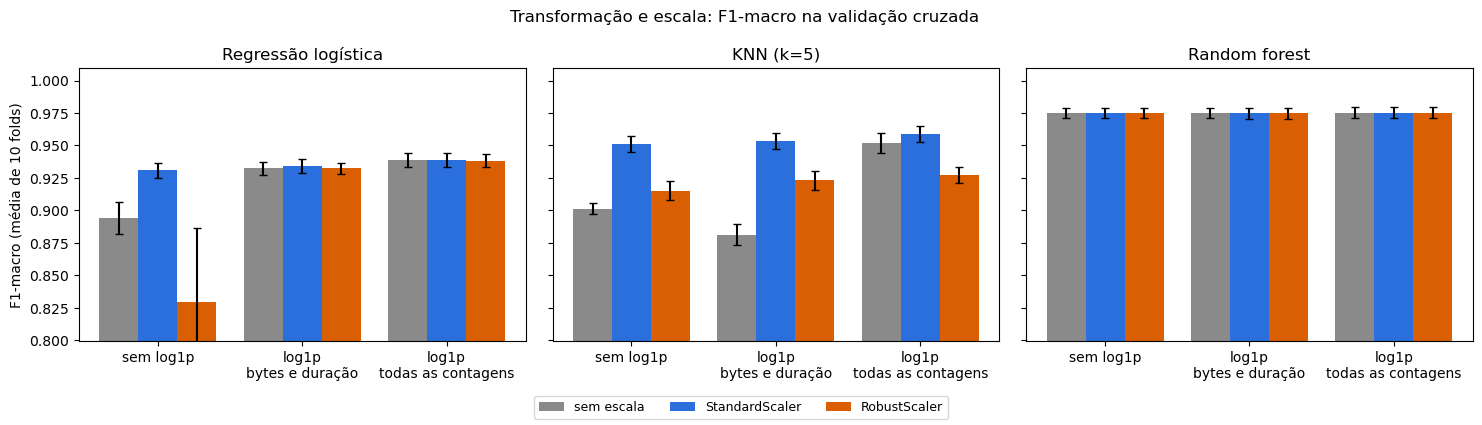

In [8]:
# gráfico 2: F1-macro de cada combinação, com o desvio entre os folds
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
cores = {"sem escala": CINZA, "StandardScaler": AZUL, "RobustScaler": LARANJA}
x = np.arange(len(OPCOES_LOG))
for ax, nome_m in zip(axes, MODELOS_P3):
    sub = comp[comp["modelo"] == nome_m]
    for k, esc in enumerate(ESCALAS):
        s = sub[sub["escala"] == esc].set_index("log1p").loc[list(OPCOES_LOG)]
        ax.bar(x + (k - 1) * 0.27, s["f1_macro"], 0.27, yerr=s["desvio"], capsize=3, color=cores[esc], label=esc)
    ax.set_xticks(x)
    ax.set_xticklabels([n.replace("log1p ", "log1p\n") for n in OPCOES_LOG])
    ax.set_title(nome_m)
axes[0].set_ylim(comp["f1_macro"].min() - 0.03, 1.01)
axes[0].set_ylabel("F1-macro (média de 10 folds)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=3, fontsize=9)
fig.suptitle("Transformação e escala: F1-macro na validação cruzada")
plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()

**Conclusão da seção 3**

- **Conferência:** a referência deu 0,9308 na logística e 0,9750 na random forest, os mesmos números da Pessoa 2. Ou seja, o pré-processamento daqui só difere do dela no que estou testando.
- **`log1p` em todas as contagens com `StandardScaler` ganhou da referência em todos os 10 folds nos dois modelos sensíveis à escala:** +0,0078 na logística (0,9386) e +0,0079 no KNN (0,9588).
- **Só bytes e duração, como pede o enunciado, ajuda menos:** +0,0033 na logística (9 de 10 folds) e +0,0025 no KNN (7 de 10). Na random forest fica em −0,0001, então não passa na regra por muito pouco.
- **Na random forest nada disso faz diferença:** as 9 combinações ficam entre 0,9748 e 0,9751. As árvores só olham a ordem dos valores, e o `log1p` e os escaladores não mudam essa ordem.
- **O `RobustScaler` é o que mais sofre sem `log1p`:** 0,8292 na logística, com o maior desvio da tabela (0,057) e −0,1016 em relação à referência. É o efeito da seção 2: com IQR = 0, os valores extremos continuam lá. Com `log1p` em todas as contagens ele se recupera na logística (0,9381), mas não no KNN (0,9272, −0,0236 e 0 de 10 folds), porque continua deixando as 25 colunas sem escala.
- **No KNN, escalar é indispensável.** O KNN mede distâncias, e a coluna com números maiores manda. Sem escala ele fica em 0,9012, e com `log1p` só nos bytes cai ainda mais (0,8812), provavelmente porque as outras contagens, que vão até 511, passam a dominar a distância.
- **A escala também pesa no tempo da logística:** sem `log1p`, sem escala ou com `RobustScaler`, o treino de um fold leva de dezenas de segundos a mais de um minuto, contra uns 2 s com `StandardScaler`. Os tempos variam a cada execução, mas a diferença é sempre grande.

**Escolha: `log1p` em todas as contagens + `StandardScaler`** (`T.montar_preprocessador(T.COLS_LOG_CONTAGENS, "standard")`). Duas combinações passaram na regra: esta e a mesma sem escala. Fico com o `StandardScaler` porque ele é bem melhor no KNN (+0,0079 contra +0,0010) e não perde em nenhum dos outros dois modelos. É essa configuração que uso como base para o PCA na próxima seção.

## 4. Redução de dimensionalidade com PCA

Depois do pré-processamento escolhido, cada linha vira um vetor com as 37 numéricas mais as colunas do one-hot. O PCA troca essas colunas por um número menor de combinações lineares delas (os componentes), escolhidas para guardar o máximo possível da **variância**. É não supervisionado: não olha a classe. Como depende da escala, ele entra depois do `StandardScaler`.

Primeiro vejo quantos componentes são precisos para guardar 80%, 90%, 95% e 99% da variância. Esse ajuste no treino inteiro serve só para o gráfico; na avaliação o PCA é ajustado dentro de cada fold, como o resto.

colunas depois do pré-processamento: 69
componentes para guardar a variância: {'80%': 18, '90%': 24, '95%': 28, '99%': 37}


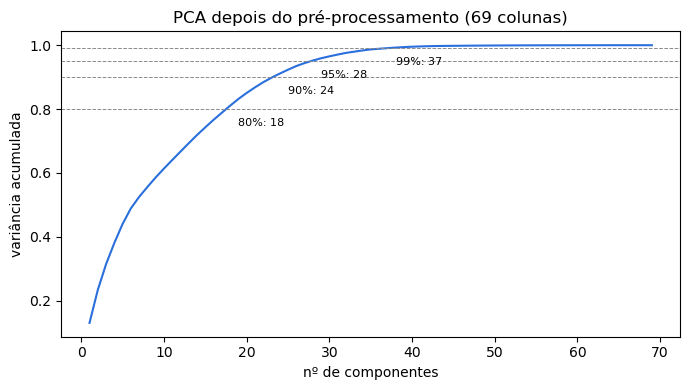

In [9]:
PRE_ESCOLHIDO = dict(cols_log=T.COLS_LOG_CONTAGENS, escalador="standard")

Z = T.montar_preprocessador(**PRE_ESCOLHIDO).fit_transform(X)
var_acum = np.cumsum(PCA().fit(Z).explained_variance_ratio_)
n_para = {f"{q:.0%}": int(np.searchsorted(var_acum, q) + 1) for q in [0.80, 0.90, 0.95, 0.99]}
print("colunas depois do pré-processamento:", Z.shape[1])
print("componentes para guardar a variância:", n_para)

# gráfico 3: variância acumulada
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(np.arange(1, len(var_acum) + 1), var_acum, color=AZUL)
for q, k in n_para.items():
    ax.axhline(float(q[:-1]) / 100, color=CINZA, lw=0.7, ls="--")
    ax.annotate(f"{q}: {k}", (k, float(q[:-1]) / 100), xytext=(6, -12), textcoords="offset points", fontsize=8)
ax.set_xlabel("nº de componentes")
ax.set_ylabel("variância acumulada")
ax.set_title(f"PCA depois do pré-processamento ({Z.shape[1]} colunas)")
plt.tight_layout(); plt.show()

Agora comparo, nos três modelos, o pipeline sem PCA (a referência daqui) com o PCA guardando 90%, 95% e 99% da variância, e com números fixos de componentes (5, 10 e 20). O possível ganho de tempo, que é onde o PCA costuma ajudar o KNN, fica para a seção 5.

In [10]:
OPCOES_PCA = {"PCA 90%": 0.90, "PCA 95%": 0.95, "PCA 99%": 0.99, "PCA 5": 5, "PCA 10": 10, "PCA 20": 20}

def n_colunas(pre):
    # quantas colunas chegam no modelo (ajuste no treino inteiro, só para contar)
    return pre.fit_transform(X).shape[1]

tec_pca = {"sem PCA": T.montar_preprocessador(**PRE_ESCOLHIDO)}
for nome, k in OPCOES_PCA.items():
    tec_pca[nome] = T.com_pca(T.montar_preprocessador(**PRE_ESCOLHIDO), k)

pca_tudo = comparar_p3(tec_pca, "sem PCA")
pca_tudo["colunas"] = pca_tudo["técnica"].map({t: n_colunas(p) for t, p in tec_pca.items()})
display(pca_tudo[["modelo", "técnica", "colunas", "f1_macro", "desvio", "dif", "ganhou"]].round(4))
print("Passam na regra:", regra_p3(pca_tudo, "sem PCA"))

,modelo,técnica,colunas,f1_macro,desvio,dif,ganhou
0,Regressão logística,sem PCA,69,0.9386,0.0054,0.0000,0
1,Regressão logística,PCA 90%,24,0.9027,0.0056,-0.0359,0
2,Regressão logística,PCA 95%,28,0.9054,0.0080,-0.0332,0
3,Regressão logística,PCA 99%,37,0.9041,0.0057,-0.0345,0
4,Regressão logística,PCA 5,5,0.9016,0.0045,-0.0370,0
5,Regressão logística,PCA 10,10,0.8956,0.0058,-0.0430,0
6,Regressão logística,PCA 20,20,0.8916,0.0064,-0.0470,0
7,KNN (k=5),sem PCA,69,0.9588,0.0061,0.0000,0
8,KNN (k=5),PCA 90%,24,0.9509,0.0077,-0.0078,0
9,KNN (k=5),PCA 95%,28,0.9525,0.0079,-0.0063,0


modelo,Regressão logística,KNN (k=5),Random forest,passa
técnica,,,,
sem PCA,referência,referência,referência,referência
PCA 90%,-0.0359 (0/10),-0.0078 (0/10),-0.0252 (0/10),False
PCA 95%,-0.0332 (0/10),-0.0063 (0/10),-0.0244 (0/10),False
PCA 99%,-0.0345 (0/10),-0.0046 (0/10),-0.0228 (0/10),False
PCA 5,-0.0370 (0/10),-0.0310 (0/10),-0.0463 (0/10),False
PCA 10,-0.0430 (0/10),-0.0164 (0/10),-0.0272 (0/10),False
PCA 20,-0.0470 (0/10),-0.0098 (0/10),-0.0233 (0/10),False


Passam na regra: []


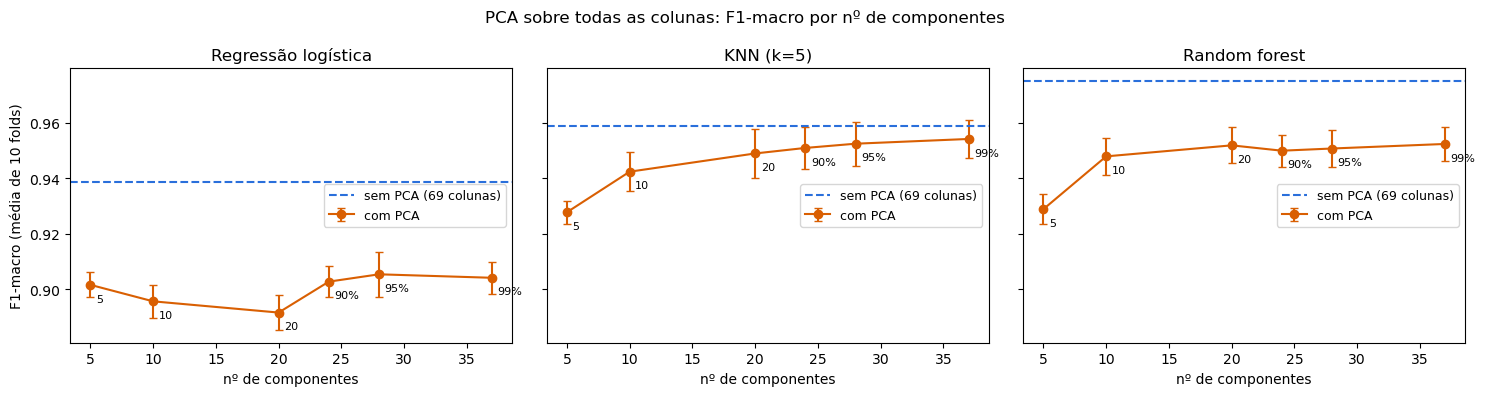

In [11]:
# gráfico 4: F1-macro x nº de colunas que chegam no modelo
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, nome_m in zip(axes, MODELOS_P3):
    s = pca_tudo[(pca_tudo["modelo"] == nome_m) & (pca_tudo["técnica"] != "sem PCA")].sort_values("colunas")
    base = pca_tudo[(pca_tudo["modelo"] == nome_m) & (pca_tudo["técnica"] == "sem PCA")].iloc[0]
    ax.errorbar(s["colunas"], s["f1_macro"], yerr=s["desvio"], marker="o", capsize=3, color=LARANJA, label="com PCA")
    ax.axhline(base["f1_macro"], color=AZUL, ls="--", label=f"sem PCA ({base['colunas']} colunas)")
    for _, l in s.iterrows():
        ax.annotate(l["técnica"].replace("PCA ", ""), (l["colunas"], l["f1_macro"]), xytext=(4, -12), textcoords="offset points", fontsize=8)
    ax.set_xlabel("nº de componentes")
    ax.set_title(nome_m)
    ax.legend(loc="center right", fontsize=9)
axes[0].set_ylabel("F1-macro (média de 10 folds)")
fig.suptitle("PCA sobre todas as colunas: F1-macro por nº de componentes")
plt.tight_layout(); plt.show()

**Conclusão da seção 4**

- Depois do pré-processamento são 69 colunas (37 numéricas e 32 do one-hot). Com 28 componentes o PCA já guarda 95% da variância, e com 37, 99%: dá para quase cortar as colunas pela metade "perdendo" pouca variância.
- **Mas o F1-macro caiu nos três modelos, em todos os 10 folds, com qualquer número de componentes.** Nenhuma opção passou na regra.
- A maior perda na comparação entre as melhores opções é da regressão logística: de 0,9386 sem PCA para no máximo 0,9054 (95%), −0,0332. Guardar 99% da variância (0,9041) não ajuda em relação a 90% (0,9027).
- A **random forest**, o modelo mais forte, também perde bastante: de 0,9751 para no máximo 0,9524 (99%), −0,0228.
- No KNN a perda é menor (0,9588 sem PCA e 0,9542 com 99%), mas cresce com poucos componentes: 0,9277 com 5.
- Perder 1% da variância e 0,02 a 0,03 de F1 ao mesmo tempo indica que parte da informação útil está em direções de **pouca** variância. A seção 5 investiga isso.

## 5. Por que o PCA perdeu informação

O PCA guarda as direções de maior variância, mas **variância não é o mesmo que poder de separar as classes**. Depois do `StandardScaler`, cada numérica tem variância 1. Já uma coluna do one-hot com proporção *p* de uns tem variância *p*(1 − *p*), que é muito pequena para as categorias raras. Comparo quanto da variância total vem de cada grupo e se as categorias de `service` dizem algo sobre a classe.

In [12]:
n_num = len(NUM)
var_col = Z.var(axis=0)
print(f"variância total: {var_col.sum():.1f}")
print(f"  numéricas ({n_num} colunas): {var_col[:n_num].sum():.1f} ({var_col[:n_num].sum() / var_col.sum():.1%})")
print(f"  one-hot ({Z.shape[1] - n_num} colunas): {var_col[n_num:].sum():.1f} ({var_col[n_num:].sum() / var_col.sum():.1%})")

# serviços com mais anomalias, entre os que têm coluna própria no one-hot (50 linhas ou mais)
por_servico = treino_limpo.groupby("service")["class"].agg(linhas="size", pct_anomalias=lambda s: (s == "anomaly").mean() * 100)
por_servico["variância no one-hot"] = (por_servico["linhas"] / len(treino_limpo)) * (1 - por_servico["linhas"] / len(treino_limpo))
display(por_servico[por_servico["linhas"] >= 50].sort_values("pct_anomalias", ascending=False).head(8).round(4))

variância total: 38.1
  numéricas (37 colunas): 37.0 (97.2%)
  one-hot (32 colunas): 1.1 (2.8%)


,linhas,pct_anomalias,variância no one-hot
service,,,
private,1762,34.4495,0.0310
ecr_i,212,32.5472,0.0038
eco_i,402,25.1244,0.0072
time,59,20.3390,0.0011
pop_3,148,12.8378,0.0027
telnet,672,10.7143,0.0121
auth,171,10.5263,0.0031
finger,438,7.3059,0.0079


Se o problema é o PCA misturar as colunas do one-hot com as numéricas, a solução é aplicar o PCA **só nas numéricas** e deixar o one-hot passar direto. É o que faz `T.montar_preprocessador(..., pca_numericas=k)`.

In [13]:
tec_num = {"sem PCA": T.montar_preprocessador(**PRE_ESCOLHIDO)}
for q in [0.90, 0.95, 0.99]:
    tec_num[f"PCA {q:.0%} (só numéricas)"] = T.montar_preprocessador(**PRE_ESCOLHIDO, pca_numericas=q)

pca_num = comparar_p3(tec_num, "sem PCA")
pca_num["colunas"] = pca_num["técnica"].map({t: n_colunas(p) for t, p in tec_num.items()})
display(pca_num[["modelo", "técnica", "colunas", "f1_macro", "desvio", "dif", "ganhou"]].round(4))
print("Passam na regra:", regra_p3(pca_num, "sem PCA"))

,modelo,técnica,colunas,f1_macro,desvio,dif,ganhou
0,Regressão logística,sem PCA,69,0.9386,0.0054,0.0000,0
1,Regressão logística,PCA 90% (só numéricas),55,0.9386,0.0061,-0.0000,6
2,Regressão logística,PCA 95% (só numéricas),59,0.9386,0.0049,-0.0000,5
3,Regressão logística,PCA 99% (só numéricas),65,0.9384,0.0046,-0.0002,5
4,KNN (k=5),sem PCA,69,0.9588,0.0061,0.0000,0
5,KNN (k=5),PCA 90% (só numéricas),55,0.9585,0.0081,-0.0002,4
6,KNN (k=5),PCA 95% (só numéricas),59,0.9610,0.0071,0.0022,9
7,KNN (k=5),PCA 99% (só numéricas),65,0.9598,0.0068,0.0011,6
8,Random forest,sem PCA,69,0.9751,0.0043,0.0000,0
9,Random forest,PCA 90% (só numéricas),55,0.9641,0.0062,-0.0110,0


modelo,Regressão logística,KNN (k=5),Random forest,passa
técnica,,,,
sem PCA,referência,referência,referência,referência
PCA 90% (só numéricas),-0.0000 (6/10),-0.0002 (4/10),-0.0110 (0/10),False
PCA 95% (só numéricas),-0.0000 (5/10),+0.0022 (9/10),-0.0118 (0/10),False
PCA 99% (só numéricas),-0.0002 (5/10),+0.0011 (6/10),-0.0125 (0/10),False


Passam na regra: []


Falta ver se o PCA compensa em tempo no KNN. Os tempos da validação cruzada não servem para isso, porque os folds rodam em paralelo e um atrapalha o outro. Então meço à parte: treino em um fold e cronometro só a previsão, sem paralelismo, três vezes, ficando com a menor.

In [14]:
def tempo_previsao(pre):
    i_tr, i_va = next(CV.split(X, y))
    pipe = Pipeline([("pre", pre), ("modelo", KNeighborsClassifier(n_neighbors=5))]).fit(X.iloc[i_tr], y.iloc[i_tr])
    tempos = []
    for _ in range(3):
        t0 = perf_counter()
        pipe.predict(X.iloc[i_va])
        tempos.append(perf_counter() - t0)
    return min(tempos)

medir = {"sem PCA": tec_pca["sem PCA"], "PCA 95%": tec_pca["PCA 95%"],
         "PCA 95% (só numéricas)": tec_num["PCA 95% (só numéricas)"], "PCA 5": tec_pca["PCA 5"]}
display(pd.Series({t: tempo_previsao(p) for t, p in medir.items()}, name="previsão de um fold no KNN (s)").round(2).to_frame())

,previsão de um fold no KNN (s)
sem PCA,0.89
PCA 95%,0.63
PCA 95% (só numéricas),0.85
PCA 5,0.17


**Conclusão da seção 5**

- Depois do `StandardScaler`, as 37 numéricas somam 97,2% da variância total e as 32 colunas do one-hot só 2,8%. Para o PCA, as categorias quase não existem.
- Só que várias categorias de `service` separam bem as classes: `private` tem 34% de anomalias, `ecr_i` 33% e `eco_i` 25%, contra 3,3% na base toda. Mesmo assim, a coluna de `private` tem variância 0,03, e as outras ainda menos. **Variância baixa não quer dizer pouca informação sobre a classe**, e o PCA, por ser não supervisionado, não tem como saber disso.
- Aplicando o PCA **só nas numéricas**, a logística volta ao nível de sem PCA (diferença de no máximo 0,0002) e o KNN até melhora um pouco com 95% (+0,0022, 9 de 10 folds). Isso confirma que boa parte do problema na logística e no KNN era misturar o one-hot.
- **Mas a random forest continua perdendo:** −0,0110 a −0,0125, em todos os 10 folds. Então o one-hot não explica tudo. A explicação provável, que não testei à parte, é que as árvores cortam uma coluna por vez, e o PCA troca colunas com sentido próprio por misturas de todas elas, em que esses cortes ficam mais difíceis. Por isso nenhuma opção passou na regra.
- **O ganho de tempo é pequeno.** Medindo isolado, a previsão de um fold no KNN leva cerca de 0,9 s sem PCA, 0,6 s com PCA 95% em todas as colunas e 0,85 s com PCA 95% só nas numéricas (os tempos variam com a carga da máquina, mas a proporção é essa). Só com 5 componentes ela fica bem mais rápida (cerca de 0,2 s), mas aí o F1 cai para 0,9277.

## 6. Conferindo a escolha no teste

Ajusto o pré-processamento escolhido no treino e aplico no teste, para ver se nada quebra. O `log1p` é a parte que pede cuidado: um valor negativo viraria `NaN` ou infinito, e a limpeza da Pessoa 1 só corrige negativos em `duration`, `src_bytes` e `dst_bytes`.

In [15]:
teste_limpo = pd.read_csv(PASTA / "teste_limpo.csv")
X_teste = teste_limpo[X.columns]

pre_p3 = T.montar_preprocessador(**PRE_ESCOLHIDO).fit(X, y)
Zt_treino, Zt_teste = pre_p3.transform(X), pre_p3.transform(X_teste)

conferencias = {
    "nenhum negativo nas colunas do log1p (treino e teste)": bool((X[T.COLS_LOG_CONTAGENS].min() >= 0).all() and (X_teste[T.COLS_LOG_CONTAGENS].min() >= 0).all()),
    "nenhum NaN ou infinito na saída (treino e teste)": bool(np.isfinite(Zt_treino).all() and np.isfinite(Zt_teste).all()),
    "teste continua com 24.333 linhas": Zt_teste.shape[0] == 24333,
    "treino e teste com as mesmas colunas": Zt_treino.shape[1] == Zt_teste.shape[1],
    "mesmas colunas da escolha da Pessoa 2 (69)": Zt_treino.shape[1] == 69,
}
for nome, ok in conferencias.items():
    print("OK  " if ok else "ERRO", nome)
assert all(conferencias.values())

OK   nenhum negativo nas colunas do log1p (treino e teste)
OK   nenhum NaN ou infinito na saída (treino e teste)
OK   teste continua com 24.333 linhas
OK   treino e teste com as mesmas colunas
OK   mesmas colunas da escolha da Pessoa 2 (69)


## 7. Resumo e escolha

In [16]:
# resultado de cada etapa, para a tabela comparativa geral da Pessoa 4
resumo_p3 = pd.concat([
    comp[comp["técnica"] == "sem log1p | sem escala"].assign(etapa="sem log1p e sem escala"),
    comp[comp["técnica"] == REF_ESCALA].assign(etapa="sem log1p + StandardScaler (Pessoa 2)"),
    comp[comp["técnica"] == "log1p todas as contagens | StandardScaler"].assign(etapa="log1p contagens + StandardScaler"),
    pca_tudo[pca_tudo["técnica"] == "PCA 95%"].assign(etapa="+ PCA 95% (todas as colunas)"),
    pca_num[pca_num["técnica"] == "PCA 95% (só numéricas)"].assign(etapa="+ PCA 95% (só numéricas)"),
])
resumo_p3["F1-macro"] = resumo_p3["f1_macro"].map("{:.4f}".format) + " ± " + resumo_p3["desvio"].map("{:.4f}".format)
display(resumo_p3.pivot(index="etapa", columns="modelo", values="F1-macro").loc[resumo_p3["etapa"].unique(), list(MODELOS_P3)])

modelo,Regressão logística,KNN (k=5),Random forest
etapa,,,
sem log1p e sem escala,0.8942 ± 0.0122,0.9012 ± 0.0044,0.9750 ± 0.0040
sem log1p + StandardScaler (Pessoa 2),0.9308 ± 0.0057,0.9508 ± 0.0061,0.9750 ± 0.0041
log1p contagens + StandardScaler,0.9386 ± 0.0054,0.9588 ± 0.0061,0.9751 ± 0.0043
+ PCA 95% (todas as colunas),0.9054 ± 0.0080,0.9525 ± 0.0079,0.9507 ± 0.0066
+ PCA 95% (só numéricas),0.9386 ± 0.0049,0.9610 ± 0.0071,0.9633 ± 0.0072


**Conclusão**

| Técnica | O que aconteceu | Decisão |
|---|---|---|
| `log1p` | Reduz a assimetria dos bytes e da duração de mais de 100 para menos de 1. Em todas as 16 contagens, ganha +0,0078 na logística e +0,0079 no KNN (10 de 10 folds); a random forest não muda. | **Usar**, em todas as contagens (`T.COLS_LOG_CONTAGENS`). |
| `StandardScaler` × `RobustScaler` | O `RobustScaler` não escala as 25 colunas com IQR = 0, vai muito mal sem `log1p` e continua pior no KNN (0,9272 contra 0,9588). Na random forest os dois empatam. | **`StandardScaler`**. |
| PCA em todas as colunas | Guarda 95% da variância com 28 de 69 colunas, mas perde F1 nos três modelos: −0,0332 na logística, −0,0244 na random forest e −0,0063 no KNN (com 95%). | **Não usar.** |
| PCA só nas numéricas | Mantém a logística e melhora um pouco o KNN, mas tira cerca de 0,012 da random forest e reduz pouco (69 → 59 colunas com 95%). | **Não usar.** |

**Pipeline recomendado:** `T.montar_preprocessador(T.COLS_LOG_CONTAGENS, "standard")`, sem PCA. F1-macro de 0,9386 na regressão logística, 0,9588 no KNN e 0,9751 na random forest, contra 0,9308, 0,9508 e 0,9750 só com o `StandardScaler`.

**Para a Pessoa 4:**
- Essa função já inclui a imputação e a codificação escolhidas pela Pessoa 2 (mediana, moda e one-hot com raras juntas), então ela entra **no lugar** do `montar_preprocessador` de `ausentes_codificacao.py`, como primeiro passo do pipeline. São as mesmas 69 colunas.
- Se o modelo final for a random forest, o `log1p` e o `StandardScaler` não mudam o resultado, mas também não atrapalham. O PCA atrapalha, e isso já foi medido aqui.
- O SMOTE trabalha com distâncias, então a escala deve importar para ele como importa para o KNN. Isso eu não testei; fica para a comparação de balanceamento.
- `score_ids_legado` ficou de fora em todos os testes daqui, e a `avaliar_p3` é provisória até sair a `avaliar()` da Pessoa 1.